# Simulación Multiactivo y Portafolios

---
Nombre: **Alan Jesús Hernández Soto**  
Carrera: **Ingeniería Financiera**  
Materia: **Simulación de Procesos Financieros**  
Tipo de trabajo: **Clase**

---

In [29]:
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import pandas as pd

capital = 100000
tickers = ['NVDA', 'BIMBOA.MX', 'CEMEXCPO.MX', 'AZN']
w = np.ones(len(tickers)) / len(tickers)

prices = yf.download(tickers, start='2023-11-02', end='2026-11-02')['Close']
forex = yf.download('USDMXN=X', start='2023-11-02', end='2026-11-02')['Close']
prices.loc[pd.Timestamp('2026-11-02'), 'BIMBOA.MX'] = 66.18
prices.loc[pd.Timestamp('2026-11-02'), 'NVDA'] = 202.60
prices.loc[pd.Timestamp('2026-11-02'), 'CEMEXCPO.MX'] = 20.23
prices.loc[pd.Timestamp('2026-11-02'), 'AZN'] = 186.58
forex.loc[pd.Timestamp('2026-11-02')] = 18.58

C:\Users\1\AppData\Local\Temp\ipykernel_36904\186096221.py:10: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(tickers, start='2023-11-02', end='2026-11-02')['Close']
[*********************100%***********************]  4 of 4 completed
C:\Users\1\AppData\Local\Temp\ipykernel_36904\186096221.py:11: FutureWarning: YF.download() has changed argument auto_adjust default to True
  forex = yf.download('USDMXN=X', start='2023-11-02', end='2026-11-02')['Close']
[*********************100%***********************]  1 of 1 completed


In [30]:
def final_price(S0, mean, std, T, sims):
    return S0 * np.exp(mean * T + std * np.sqrt(T) * np.random.normal(size=sims))

# def final_price(S0, mean, std, T, sims):
#     return S0 * np.exp((mean - 0.5 * std**2) * T + std * np.sqrt(T) * np.random.normal(size=sims))

## Forex

In [31]:
forex_returns = np.log(forex / forex.shift(1)).dropna()
mean_forex = forex_returns.mean()*252
std_forex = forex_returns.std()*np.sqrt(252)
S0_forex = forex.loc[pd.Timestamp('2026-11-02')].values[0]

st_forex_dis = final_price(S0_forex, mean_forex.values[0], std_forex.values[0], 1, 10000)
st_forex = np.mean(st_forex_dis)
print(f"Cambio hoy USD/MXN: {S0_forex:.2f}")
print(f"Cambio Esperado USD/MXN en 2027: {st_forex:.2f}")

Cambio hoy USD/MXN: 18.58
Cambio Esperado USD/MXN en 2027: 19.00


## A. Solo NVDA

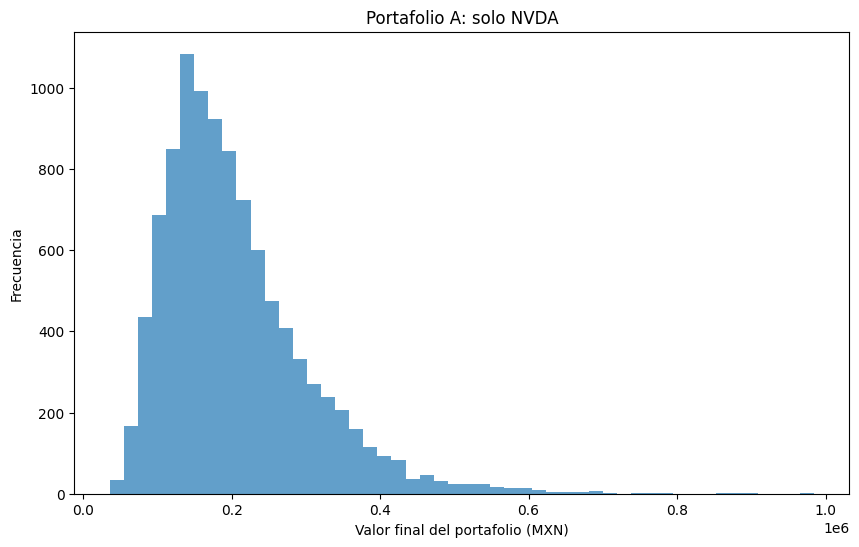

Valor del portafolio actual: 100000.00 MXN
Valor del portafolio en 2027: 204509.24 MXN
Rendimiento Portafolio: 104.51%


In [45]:
np.random.seed(67)

w = 1
S0 = prices['NVDA'].iloc[-1]
S0_mxn = S0 * S0_forex

cap = w * capital
N0 = np.floor(cap / S0_mxn)
cash = capital - N0 * S0_mxn

prices_nvda = prices['NVDA']
lg_rets = np.log(prices_nvda / prices_nvda.shift(1)).dropna()
mean = lg_rets.mean() * 252
std = lg_rets.std() * np.sqrt(252)

T = 1
sims = 10000
st_dis = final_price(S0, mean, std, T, sims)
vt_dis = st_dis * st_forex * N0 + cash
vt = np.mean(vt_dis)

plt.figure(figsize=(10, 6))
plt.hist(vt_dis, bins=50, alpha=0.7)
plt.xlabel('Valor final del portafolio (MXN)')
plt.ylabel('Frecuencia')
plt.title('Portafolio A: solo NVDA')
plt.show()

print(f'Valor del portafolio actual: {capital:.2f} MXN')
print(f'Valor del portafolio en 2027: {vt:.2f} MXN')
print(f'Rendimiento Portafolio: {(vt - capital) / capital * 100:.2f}%')

vt_A_ind = vt_dis.copy()

## B. Portafolio Equiponderado

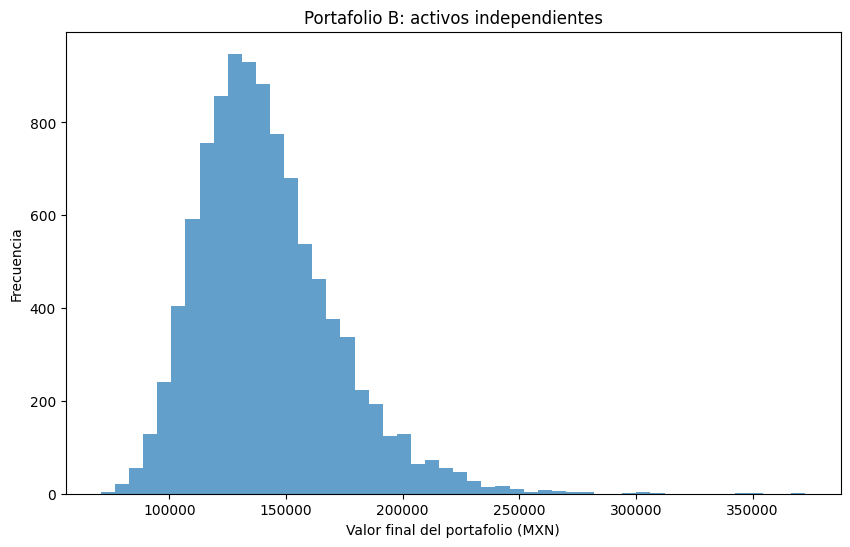

Valor del portafolio actual: 100000.00 MXN
Valor del portafolio en 2027: 141695.27 MXN
Rendimiento Portafolio: 41.70%


In [46]:
w = np.array([0.25, 0.25, 0.25, 0.25])
S0 = prices.iloc[-1].copy()
S0.loc[['AZN', 'NVDA']] = S0.loc[['AZN', 'NVDA']] * S0_forex

cap = w * capital
N0 = np.floor(cap / S0)
cash = capital - np.sum(N0 * S0)


lg_rets = np.log(prices / prices.shift(1)).dropna()
T = 1
sims = 10000
vt_dis = np.full(sims, cash)


for ticker in tickers:
    S0 = prices[ticker].iloc[-1]
    returns = lg_rets[ticker]
    mean = returns.mean()*252
    std = returns.std()*np.sqrt(252)
    st_dis = final_price(S0, mean, std, T, sims)
    if ticker in ['AZN', 'NVDA']:
        st_dis = st_dis * st_forex
    vt_dis = vt_dis + st_dis * N0[ticker]


vt = np.mean(vt_dis)

plt.figure(figsize=(10, 6))
plt.hist(vt_dis, bins=50, alpha=0.7)
plt.xlabel('Valor final del portafolio (MXN)')
plt.ylabel('Frecuencia')
plt.title('Portafolio B: activos independientes')
plt.show()

print(f'Valor del portafolio actual: {capital:.2f} MXN')
print(f'Valor del portafolio en 2027: {vt:.2f} MXN')
print(f'Rendimiento Portafolio: {(vt - capital) / capital * 100:.2f}%')

vt_B_ind = vt_dis.copy()

## C. Portafolio de Pesos Crecientes

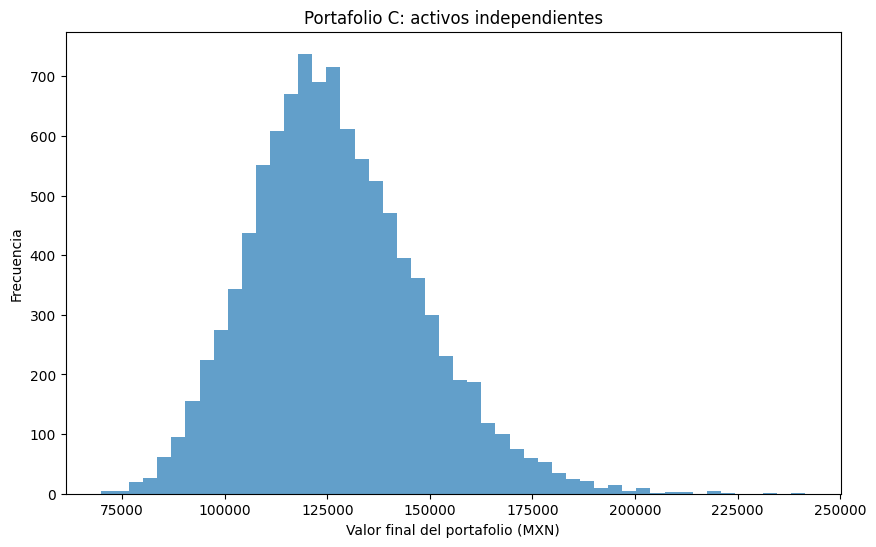

Valor del portafolio actual: 100000.00 MXN
Valor del portafolio en 2027: 127149.02 MXN
Rendimiento Portafolio: 27.15%


In [47]:
w = np.array([0.1, 0.2, 0.3, 0.4])
S0 = prices.loc[:, tickers].iloc[-1].copy()
S0.loc[['AZN', 'NVDA']] = S0.loc[['AZN', 'NVDA']] * S0_forex

cap = w * capital
N0 = np.floor(cap / S0)
cash = capital - np.sum(N0 * S0)

lg_rets = np.log(prices / prices.shift(1)).dropna()
T = 1
sims = 10000
vt_dis = np.full(sims, cash)


for ticker in tickers:
    S0 = prices[ticker].iloc[-1]
    returns = lg_rets[ticker]
    mean = returns.mean()*252
    std = returns.std()*np.sqrt(252)
    st_dis = final_price(S0, mean, std, T, sims)
    if ticker in ['AZN', 'NVDA']:
        st_dis = st_dis * st_forex
    vt_dis = vt_dis + st_dis * N0[ticker]


vt = np.mean(vt_dis)

plt.figure(figsize=(10, 6))
plt.hist(vt_dis, bins=50, alpha=0.7)
plt.xlabel('Valor final del portafolio (MXN)')
plt.ylabel('Frecuencia')
plt.title('Portafolio C: activos independientes')
plt.show()

print(f'Valor del portafolio actual: {capital:.2f} MXN')
print(f'Valor del portafolio en 2027: {vt:.2f} MXN')
print(f'Rendimiento Portafolio: {(vt - capital) / capital * 100:.2f}%')

vt_C_ind = vt_dis.copy()

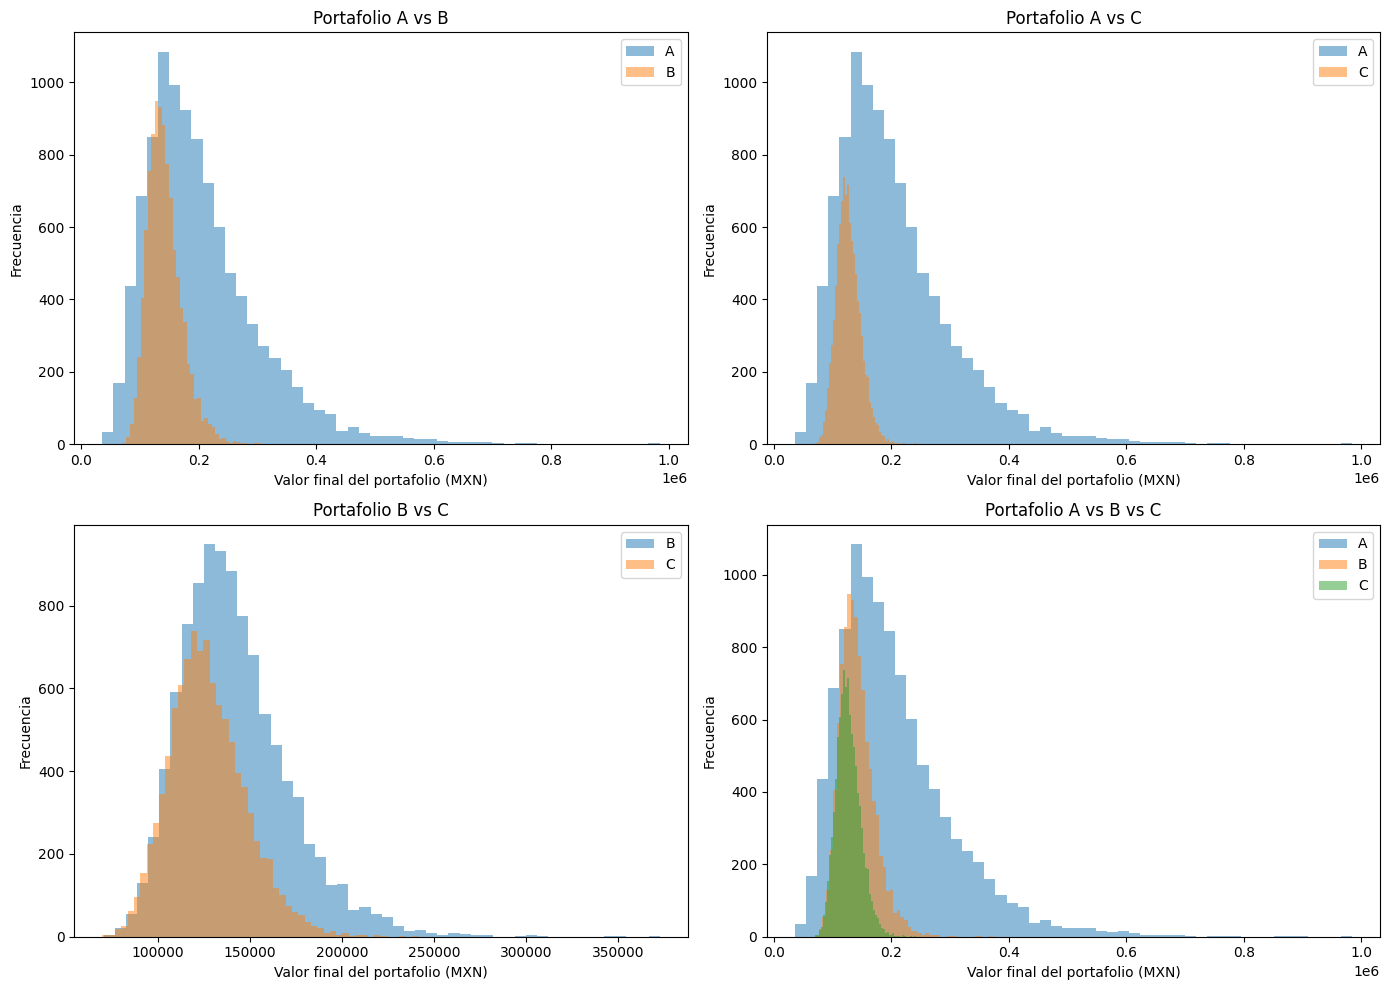

In [50]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))

# A vs B
ax[0, 0].hist(vt_A_ind, bins=50, alpha=0.5, label='A')
ax[0, 0].hist(vt_B_ind, bins=50, alpha=0.5, label='B')
ax[0, 0].set_title('Portafolio A vs B')
ax[0, 0].legend()

# A vs C
ax[0, 1].hist(vt_A_ind, bins=50, alpha=0.5, label='A')
ax[0, 1].hist(vt_C_ind, bins=50, alpha=0.5, label='C')
ax[0, 1].set_title('Portafolio A vs C')
ax[0, 1].legend()

# B vs C
ax[1, 0].hist(vt_B_ind, bins=50, alpha=0.5, label='B')
ax[1, 0].hist(vt_C_ind, bins=50, alpha=0.5, label='C')
ax[1, 0].set_title('Portafolio B vs C')
ax[1, 0].legend()

# A vs B vs C
ax[1, 1].hist(vt_A_ind, bins=50, alpha=0.5, label='A')
ax[1, 1].hist(vt_B_ind, bins=50, alpha=0.5, label='B')
ax[1, 1].hist(vt_C_ind, bins=50, alpha=0.5, label='C')
ax[1, 1].set_title('Portafolio A vs B vs C')
ax[1, 1].legend()

for grafica in ax.flat:
    grafica.set_xlabel('Valor final del portafolio (MXN)')
    grafica.set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

--- 

## Calculo de parámetros para la simulación multiactivo
A partir de la matriz de covaraianza de mis activos calculamos con Cholesky la discomposición de la matriz de covarianza en sus matrices diagonales así mismo calculamos nuestra distribución multinomial con media 0 y varianzas independientes. Con esto podemos ajustar nuestros universos de Z en una matrz de activos X universos.

In [48]:
ticker = ['AAPL', 'MSFT', 'NVDA']
prices = yf.download(ticker, start='2023-11-04', end = '2026-11-04')['Close']
rets = np.log(prices / prices.shift(1)).dropna()

M = 10000
n_act = len(ticker)
cov  = rets.cov()

L = np.linalg.cholesky(cov)
E = np.random.normal(0,1, size=(n_act, M))
Z = L @ E
Z = Z.T


C:\Users\1\AppData\Local\Temp\ipykernel_36904\4052156074.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(ticker, start='2023-11-04', end = '2026-11-04')['Close']
[*********************100%***********************]  3 of 3 completed


## GBM usando nuestra variable estocástica nueva

Dado a que tenemos nuestros universos calculamos por medio de GBM el precio final en 1 año iterando en nuestra matriz de Z.

In [49]:
T = 1
ST = np.zeros(shape=(M, n_act))
cont = 0
for ticker in prices.columns:
    S0 = prices[ticker].iloc[-1]
    mu = rets[ticker].mean()*252
    vol = rets[ticker].std()*np.sqrt(252)
    st = S0*np.exp(mu-0.5*(vol**2)*T + vol*np.sqrt(T)*Z[:, cont])
    ST[:, cont] = st
    cont += 1

ST

array([[393.83465351, 576.98855296, 304.11976861],
       [396.82148015, 574.91289582, 304.43151758],
       [396.91725847, 582.45030303, 311.3358778 ],
       ...,
       [395.55788496, 574.59351576, 303.8520266 ],
       [396.51293424, 575.36887795, 304.58876217],
       [398.46415637, 576.04492877, 300.41230996]], shape=(10000, 3))